# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

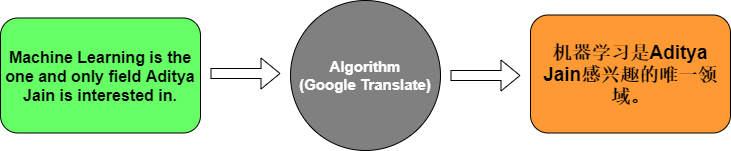

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - accuracy: 0.0000e+00 - loss: 2.4835 - val_accuracy: 0.0000e+00 - val_loss: 2.4875
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5714 - loss: 2.4751 - val_accuracy: 0.0000e+00 - val_loss: 2.4891
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.5714 - loss: 2.4663 - val_accuracy: 0.0000e+00 - val_loss: 2.4909
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step - accuracy: 0.5714 - loss: 2.4567 - val_accuracy: 0.0000e+00 - val_loss: 2.4929
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 0.5714 - loss: 2.4461 - val_accuracy: 0.0000e+00 - val_loss: 2.4951
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.5714 - loss: 2.4339 - val_accuracy: 0.0000e+00 - val_loss: 2.4976
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.5714 - loss: 2.4197 - val_accuracy: 0.0000e+00 - val_loss: 2.5005
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.5714 - loss: 2.4031 - val_

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 893ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. **Embedding layer:** It converts each word index into a numerical vector that represents the word.

2. **Encoder LSTM:** It reads the input English sentence and learns its important information and context.

3. **Decoder LSTM:** It uses the encoded information to generate the translated sentence step by step.

4. **Softmax:** It converts the final outputs into probabilities for all possible French words, so the model can choose the most likely word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
%pip install tensorflow==2.21.0

In [9]:
%pip install kagglehub -q

import kagglehub
import pandas as pd
import glob
import os

# Download dataset
path = kagglehub.dataset_download(
    "devicharith/language-translation-englishfrench"
)

# Find the CSV file
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("CSV files:", csv_files)

# Load dataset
df = pd.read_csv(csv_files[0])

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Note: you may need to restart the kernel to use updated packages.
CSV files: ['C:\\Users\\Sara Salah\\.cache\\kagglehub\\datasets\\devicharith\\language-translation-englishfrench\\versions\\2\\eng_-french.csv']
Shape: (175621, 2)
Columns: ['English words/sentences', 'French words/sentences']


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Remove missing values and use 10,000 rows
data = df[
    ['English words/sentences', 'French words/sentences']
].dropna().head(10000)

english_sentences = data['English words/sentences'].astype(str).tolist()
french_sentences = data['French words/sentences'].astype(str).tolist()

# Tokenize English
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)

# Tokenize French
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

# Padding
eng_padded = pad_sequences(eng_sequences, maxlen=20, padding='post')
frn_padded = pad_sequences(frn_sequences, maxlen=20, padding='post')

print("English shape:", eng_padded.shape)
print("French shape:", frn_padded.shape)

print("English vocabulary:", len(tokenizer_eng.word_index))
print("French vocabulary:", len(tokenizer_frn.word_index))

English shape: (10000, 20)
French shape: (10000, 20)
English vocabulary: 2146
French vocabulary: 4508


In [11]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
import numpy as np

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded,
    frn_padded,
    test_size=0.2,
    random_state=42
)

# Build the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(
        input_dim=len(tokenizer_eng.word_index) + 1,
        output_dim=64
    ),

    tf.keras.layers.LSTM(64),

    tf.keras.layers.RepeatVector(frn_padded.shape[1]),

    tf.keras.layers.LSTM(64, return_sequences=True),

    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(
            len(tokenizer_frn.word_index) + 1,
            activation='softmax'
        )
    )
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_1 (RepeatVector)       │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(
    eng_train,
    np.expand_dims(frn_train, -1),
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

# Evaluate the model
loss, accuracy = model.evaluate(
    eng_test,
    np.expand_dims(frn_test, -1)
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 48s 389ms/step - accuracy: 0.8229 - loss: 3.6136 - val_accuracy: 0.8311 - val_loss: 1.3942
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 43s 431ms/step - accuracy: 0.8312 - loss: 1.2959 - val_accuracy: 0.8311 - val_loss: 1.2447
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 397ms/step - accuracy: 0.8335 - loss: 1.1953 - val_accuracy: 0.8396 - val_loss: 1.1846
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 297ms/step - accuracy: 0.8412 - loss: 1.1476 - val_accuracy: 0.8396 - val_loss: 1.1558
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 404ms/step - accuracy: 0.8412 - loss: 1.1197 - val_accuracy: 0.8396 - val_loss: 1.1396
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 452ms/step - accuracy: 0.8415 - loss: 1.1027 - val_accuracy: 0.8396 - val_loss: 1.1305
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 35s 352ms/step - accuracy: 0.8431 - loss: 1.0910 - val_accuracy: 0.8412 - val_loss: 1.1251
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 35s 350ms/step - accuracy: 0.8437 - loss: 1